In [1]:
from jupyter_tikz import TexFragment
import os, sys
from IPython.display import display, HTML, Markdown, Math

# To find local version of the library
sys.path.append('../src')

from pmule import PredecessorTable, ProjectGraph, pinta_tikz

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

In [3]:
#| tbl-cap: "Cuadro de datos del enunciado del ejercicio"
#| label: tbl-datosEnunciado

import pandas as pd
pd.set_option('future.no_silent_downcasting', True)

import numpy as np

datos_enunciado = pd.DataFrame([
#  actividad, precedentes, duracion, duracion_tope, cur, recursos
     ('A',       '---  ',     4,         1,          25,     2    ),
     ('B',       'A    ',     4,         1,          25,     1    ),
     ('C',       'A    ',     5,         2,          20,     2    ),
     ('D',       'A    ',     4,         1,          10,     2    ),
     ('E',       'A    ',     3,         2,          50,     2    ),
     ('F',       'D,E  ',     6,         3,          30,     4    ),
     ('G',       'F    ',     4,         1,          25,     1    ),
     ('H',       'B,C,G',     7,         4,          20,     1    ),
     ('I',       'C,G  ',     5,         2,          20,     3    ),
     ('J',       'I    ',     4,         1,          25,     4    ),
     ('K',       'F    ',     4,         1,          25,     1    ),
     ('L',       'H    ',     8,         5,          10,     2    ),
     ('M',       'I,K  ',     4,         1,          25,     1    ),

] ,columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr', 'resources']).set_index('activity')

datos_enunciado

,predecessor,duration,cap_duration,ucr,resources
activity,,,,,
A,---,4,1,25,2
B,A,4,1,25,1
C,A,5,2,20,2
D,A,4,1,10,2
E,A,3,2,50,2
F,"D,E",6,3,30,4
G,F,4,1,25,1
H,"B,C,G",7,4,20,1
I,"C,G",5,2,20,3


# Solución
## Apartado 1

In [5]:
from pmule import PredecessorTable, ProjectGraph

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I,J,K,L,M
activities,,,,,,,,,,,,,
A,,,,,,,,,,,,,
B,True,,,,,,,,,,,,
C,True,,,,,,,,,,,,
D,True,,,,,,,,,,,,
E,True,,,,,,,,,,,,
F,,,,True,True,,,,,,,,
G,,,,,,True,,,,,,,
H,,True,True,,,,True,,,,,,
I,,,True,,,,True,,,,,,


In [7]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto_apartado_1 = datos_proyecto.copy() # La necesitaremos en el apartado 4

In [8]:
proyecto = prelaciones.create_project()

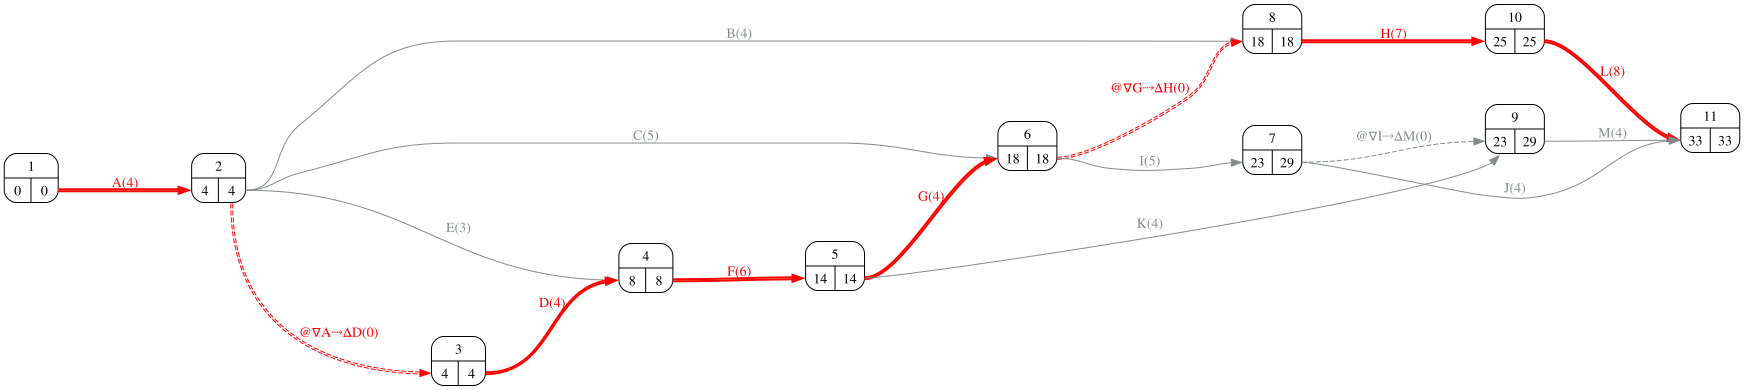

In [9]:
proyecto.pert(ranksep=1.5, nodesep=0.7, durations=datos_proyecto['duration'])

In [10]:
holguras = proyecto.calculate_pert(durations=datos_proyecto['duration'])['activities'].T

## Asignación

In [11]:
proyecto_asignacion = proyecto.copy()
my_data, gantt_df, dibujo = proyecto_asignacion.asignar(data=datos_proyecto,
                                              duration_label='duration',
                                              resource_label='resources',
                                              maximo = [3]*7 + [10],
                                              report = True,
                                              params = dict(
                                                  period_width=1
                                                  )
                                              )

<br> Periodo: 1. 

Periodo: 1. Total: 2. Se programan: ['A']

<br> Periodo: 2. 

Periodo: 2. Total: 2. Se programan: ['A']

<br> Periodo: 3. 

...

Periodo: 33. Total: 2. Se programan: ['L']

<br> Periodo: 34. 

Periodo: 34. Total: 2. Se programan: ['L']

<br> Periodo: 35. 

Periodo: 35. Total: 2. Se programan: ['L']

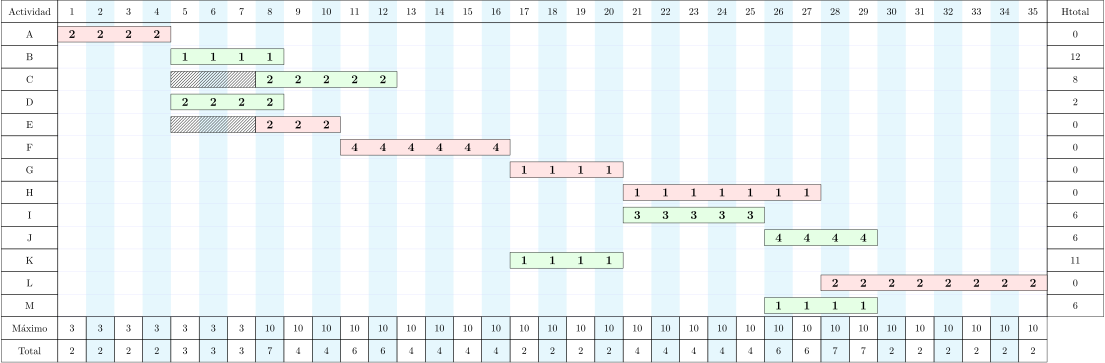

In [12]:
pinta_tikz(dibujo)